In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO')
print(os.getcwd())


/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files

In [9]:
notebook_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/notebook.jpg'
mask_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/notebook_mask.png'
coins_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/coins.jpg'
tomatoes_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/tomatoes.jpg'
rock_path = '/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac5-CHIPOMPO/images/rock.jpg'

In [4]:
def img_read(path):
  img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
  #img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  return img


**Task 1. Thresholding, honestly evaluated**

In [5]:
##############################################
# Global Threshold
##############################################
def global_threshold(image, thresh=127):
    _, mask = cv2.threshold(image, thresh, 255, cv2.THRESH_BINARY)
    return mask

##############################################
# Otsu's Method
##############################################
def otsu_threshold(image):
    _, mask = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask


##############################################
# Adaptive Thresholding
##############################################
def adaptive_mean(image, ksize=21, C=5):
    return cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, ksize, C)

def adaptive_gaussian(image, ksize=21, C=5):
    return cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, ksize, C)

##############################################
# Intersection Over Union
##############################################

def iou(pred_mask, ref_mask):
    pred_bin = pred_mask > 0
    ref_bin = ref_mask > 0
    intersection = np.logical_and(pred_bin, ref_bin).sum()
    union = np.logical_or(pred_bin, ref_bin).sum()
    return intersection / union if union > 0 else 0


Global IoU: 0.020
Otsu IoU: 0.031
Adaptive Mean IoU: 0.029
Adaptive Gaussian IoU: 0.041


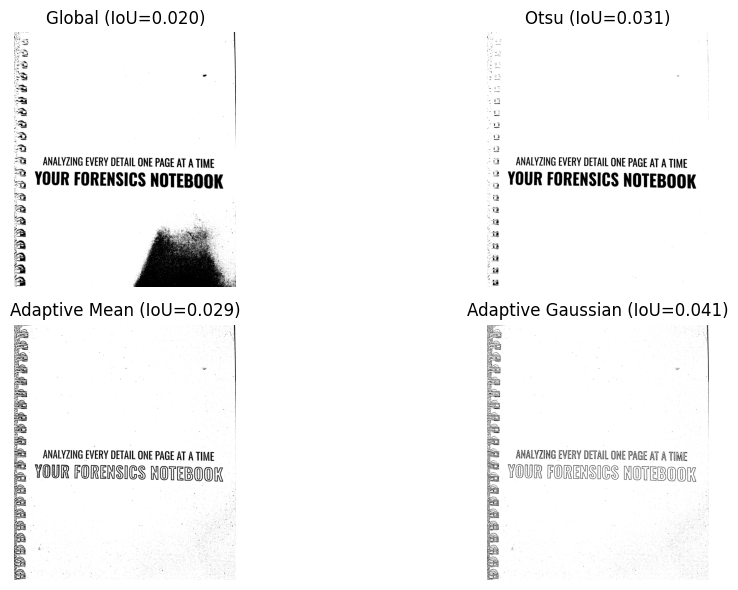

In [10]:
##############################################
# IoU Report
##############################################
methods = {
    "Global": global_threshold(image=img_read(notebook_path)),
    "Otsu": otsu_threshold(image=img_read(notebook_path)),
    "Adaptive Mean": adaptive_mean(image=img_read(notebook_path)),
    "Adaptive Gaussian": adaptive_gaussian(image=img_read(notebook_path))
}

# --- Compute IoU scores ---
scores = {name: iou(mask, ref_mask=img_read(mask_path)) for name, mask in methods.items()}

# --- Print results ---
for name, score in scores.items():
    print(f"{name} IoU: {score:.3f}")

# --- Visualize masks side by side ---
plt.figure(figsize=(12,6))
for i, (name, mask) in enumerate(methods.items(), 1):
    plt.subplot(2,2,i)
    plt.imshow(mask, cmap="gray")
    plt.title(f"{name} (IoU={scores[name]:.3f})")
    plt.axis("off")
plt.tight_layout()
plt.show()


**Task 2. Watershed for touching objects**